# Talhão 62 — Biometric Grid Search with Spatial Matching
**Workflow**
1. Load all data and run spatial alignment for every plot (show matching map)
2. User selects which plot(s) to run the full grid search on
3. Preliminary probe with default params — shows quick estimates per method
4. Full parallel grid search over all param combinations
5. Per-method results table and per-tree scatter (Real vs Estimated)
6. Top-5 extrapolation to m³/ha vs official ground truth



In [1]:
import os, warnings
import numpy as np
import pandas as pd
import laspy
from tqdm.notebook import tqdm
from concurrent.futures import ProcessPoolExecutor, as_completed
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

from eucalipto.dbh_methods import estimate_dbh
from eucalipto.volume_methods import estimate_volume

warnings.filterwarnings("ignore")



In [2]:
# ══════════════════════════════════════════════════════════
#  CONFIGURATION — edit these before running
# ══════════════════════════════════════════════════════════
RESULT_IFPC_PATH = "/mnt/scratch/matheuspimenta/euc/canoa/IFPC-Canoas/Result_IFPC_Canoas.xlsx"
TALHAO_GT        = "062-063"
ALL_PARCELAS     = [500, 503, 508, 509]
NUM_WORKERS      = 8

CLOUD_PATHS = {
    p: f"/home/matheuspimenta/euc/projeto_eucalipto/results/canoa/parcelas_t62/parcela_{p}/classified_cloud.laz"
    for p in ALL_PARCELAS
}



## 1. Helper Functions


In [3]:
# ──────────────────────────────────────────────────────────
# Data loading
# ──────────────────────────────────────────────────────────
def load_field_data(excel_path, talhao, parcelas):
    df_covas = pd.read_excel(excel_path, sheet_name="Covas")
    df_raw = df_covas[
        (df_covas["Talhão"] == talhao) &
        (df_covas["PAR_CODIGO"].isin(parcelas)) &
        df_covas["Fila"].notnull() & df_covas["Cova"].notnull()
    ].copy()

    # Reconstruct planting grid: 3.5 m row spacing (Fila), 2.5 m col spacing (Cova)
    df_raw["x_grid"] = df_raw["Cova"].astype(float) * 2.5
    df_raw["y_grid"] = df_raw["Fila"].astype(float) * 3.5

    # One row per planting hole; multi-stems summed
    df_field = df_raw.groupby(["PAR_CODIGO", "Fila", "Cova"]).agg(
        x_grid=("x_grid", "first"),
        y_grid=("y_grid", "first"),
        dap_cm=("Dap (cm)", "max"),
        gt_volume=("VTCC Volume (m³)", "sum"),
        alt_m=("Altura (m)", "max")
    ).reset_index()
    df_field["field_id"]     = (df_field["PAR_CODIGO"].astype(str) + "_"
                                + df_field["Fila"].astype(str) + "_"
                                + df_field["Cova"].astype(str))
    df_field["has_gt_volume"] = df_field["gt_volume"].notnull() & (df_field["gt_volume"] > 0)

    df_extrap = pd.read_excel(excel_path, sheet_name="Parcelas")
    df_extrap = df_extrap[
        (df_extrap["Talhão"] == talhao) & df_extrap["Parcela"].isin(parcelas)
    ].set_index("Parcela")

    return df_field, df_extrap


def load_lidar_data(cloud_paths):
    points_dict, heights_dict, trunk_masks_dict, full_masks_dict, lidar_centers = {}, {}, {}, {}, {}

    for plot_id, path in cloud_paths.items():
        lidar_centers[plot_id] = []
        if not os.path.exists(path):
            print(f"  [SKIP] {path}")
            continue

        las    = laspy.read(path)
        pts    = np.vstack((las.x, las.y, las.z)).T
        fields = list(las.point_format.dimension_names)

        inst = (np.array(las.tree_id)          if "tree_id"          in fields else
                np.array(las.instance_pred)    if "instance_pred"    in fields else
                np.zeros(len(pts), dtype=np.int32))

        sem  = (np.array(las.trunk_leaf_label) if "trunk_leaf_label" in fields else
                np.array(las.semantic_pred)    if "semantic_pred"    in fields else
                np.ones(len(pts), dtype=np.int32))

        for tid in np.unique(inst):
            if tid <= 0: continue
            mask = inst == tid
            t_pts = pts[mask]
            if len(t_pts) < 50: continue

            z0, z1 = t_pts[:, 2].min(), t_pts[:, 2].max()
            cx, cy = np.median(t_pts[:, 0]), np.median(t_pts[:, 1])

            gid = tid + plot_id * 10000
            heights_dict[gid] = float(z1 - z0)
            lidar_centers[plot_id].append({"global_tid": gid, "x": cx, "y": cy})

            # Center the cloud (z from ground, xy centered)
            t_c = t_pts.copy()
            t_c[:, 0] -= cx; t_c[:, 1] -= cy; t_c[:, 2] -= z0
            points_dict[gid]     = t_c
            trunk_masks_dict[gid] = (sem[mask] == 1)    # trunk points only

    return points_dict, heights_dict, trunk_masks_dict, lidar_centers


# ──────────────────────────────────────────────────────────
# Spatial alignment (Hungarian + 360° rotation search)
# ──────────────────────────────────────────────────────────
def _hungarian(A, B):
    mA, mB = (A.max(0) + A.min(0))/2, (B.max(0) + B.min(0))/2
    Ac, Bc = A - mA, B - mB
    best = (float("inf"), 0, None, None, None)
    for dx in [-2, -1, 0, 1, 2]:
        for dy in [-2, -1, 0, 1, 2]:
            A_shift = Ac + np.array([dx, dy])
            for deg in range(360):
                t = np.radians(deg); c, s = np.cos(t), np.sin(t)
                Br = Bc @ np.array([[c, -s],[s, c]]).T
                D  = cdist(A_shift, Br)
                ri, ci = linear_sum_assignment(D)
                cost = D[ri, ci].sum()
                if cost < best[0]:
                    best = (cost, deg, (ri, ci), Br, A_shift)
    return best[4], best[3], best[2], best[1], best[0]

def align_and_match(lidar_list, plot_df):
    L = np.array([[t["x"], t["y"]] for t in lidar_list])
    F = plot_df[["x_grid", "y_grid"]].values

    # Try both orientations (Fila/Cova might be swapped relative to the cloud)
    Lc,Fr, mi, ang, c1 = _hungarian(L, F)
    Lcs,Frs,mis,angs,c2 = _hungarian(L, F[:, [1, 0]])

    if c2 < c1:
        Lc, Fr, mi, ang = Lcs, Frs, mis, angs
        c1 = c2

    mean_err = c1 / len(mi[0])
    matches = []
    for li, fi in zip(mi[0], mi[1]):
        row = plot_df.iloc[fi]
        matches.append({
            "global_tid":   lidar_list[li]["global_tid"],
            "field_id":     row["field_id"],
            "has_gt_volume":row["has_gt_volume"],
            "gt_volume":    row["gt_volume"] if row["has_gt_volume"] else np.nan,
            "gt_dbh":       row["dap_cm"]   if row["has_gt_volume"] else np.nan,
            "gt_height":    row["alt_m"]    if row["has_gt_volume"] else np.nan,
            "plot_id":      row["PAR_CODIGO"],
        })
    return Lc, Fr, mi, ang, mean_err, matches


# ──────────────────────────────────────────────────────────
# Grid-search worker
# ──────────────────────────────────────────────────────────
def _init(pts, ht, tm):
    global _P, _H, _T
    _P, _H, _T = pts, ht, tm

def _run(args):
    tid, dm, dp, vm, vp = args
    pts, h, tmask = _P[tid], _H[tid], _T[tid]
    trunk = pts[tmask] if tmask.sum() > 10 else pts     # trunk-only for shape methods

    try:
        dbh, _ = estimate_dbh(trunk, method=dm, **dict(dp))
    except Exception:
        dbh = float("nan")

    try:
        if vm == "cylinder":
            if np.isnan(dbh): raise ValueError("NaN DBH")
            r = estimate_volume(trunk, dbh_cm=dbh, height_m=h, method="cylinder")
        elif vm in ("axis_profile", "frustum", "taper"):
            r = estimate_volume(trunk, method=vm, **dict(vp))   # trunk only!
        else:                                                     # voxel on trunk (not full cloud)
            r = estimate_volume(trunk, method=vm, **dict(vp))
        vol = r["volume_m3"]
    except Exception:
        vol = float("nan")

    return {"global_tid": tid, "dbh_method": dm, "dbh_params": str(dict(dp)),
            "volume_method": vm, "volume_params": str(dict(vp)),
            "dbh_cm": dbh, "volume_m3": vol, "height_m": h}



## 2. Load Data & Run Spatial Matching for All Plots


Loading field data…
Loading LiDAR clouds…
Parcela 500: 19 LiDAR trees matched → 19 pairs (15 with GT volume) | rot 93° | mean err 1.02 m
Parcela 503: 34 LiDAR trees matched → 34 pairs (22 with GT volume) | rot 262° | mean err 1.36 m
Parcela 508: 40 LiDAR trees matched → 40 pairs (32 with GT volume) | rot 155° | mean err 1.64 m
Parcela 509: 25 LiDAR trees matched → 25 pairs (5 with GT volume) | rot 177° | mean err 1.18 m


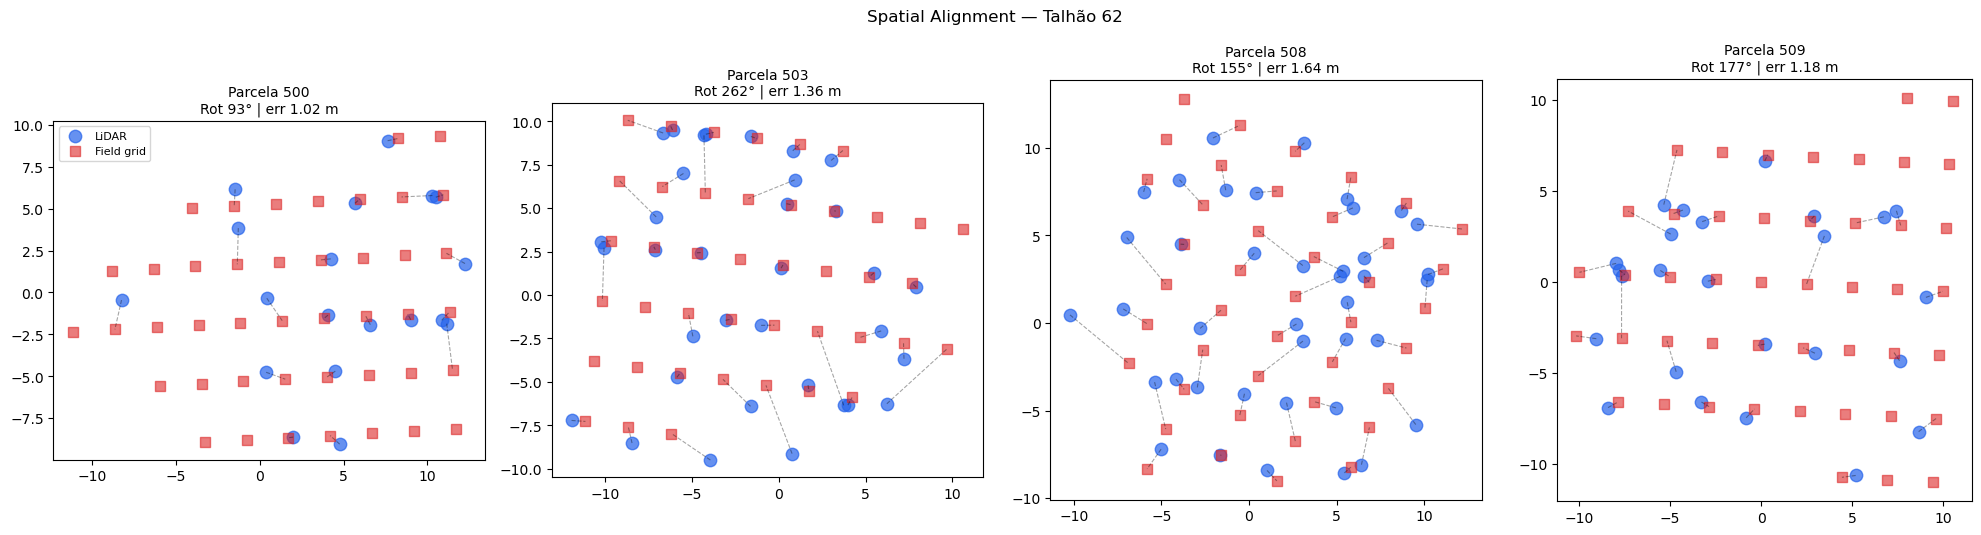


Total matched pairs: 118  |  with GT volume: 74


In [4]:
print("Loading field data…")
df_field, df_extrap = load_field_data(RESULT_IFPC_PATH, TALHAO_GT, ALL_PARCELAS)

print("Loading LiDAR clouds…")
points_dict, heights_dict, trunk_masks_dict, lidar_centers = load_lidar_data(CLOUD_PATHS)

# ── Run alignment for all plots ────────────────────────────
all_matches = []
n_plots = sum(1 for p in ALL_PARCELAS if lidar_centers.get(p))

fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 5))
if n_plots == 1: axes = [axes]
ax_iter = iter(axes)

for plot_id in ALL_PARCELAS:
    lidar_list = lidar_centers.get(plot_id, [])
    if not lidar_list:
        print(f"  [SKIP] Parcela {plot_id} — no LiDAR trees found")
        continue

    plot_df = df_field[df_field["PAR_CODIGO"] == plot_id].reset_index(drop=True)
    Lc, Fr, mi, angle, mean_err, matches = align_and_match(lidar_list, plot_df)
    all_matches.extend(matches)

    n_with_gt = sum(1 for m in matches if m["has_gt_volume"])
    print(f"Parcela {plot_id}: {len(lidar_list)} LiDAR trees matched "
          f"→ {len(matches)} pairs ({n_with_gt} with GT volume) | "
          f"rot {angle}° | mean err {mean_err:.2f} m")

    ax = next(ax_iter)
    ax.scatter(Lc[:, 0], Lc[:, 1], c="#2563eb", s=80, alpha=0.7, label="LiDAR")
    ax.scatter(Fr[:, 0], Fr[:, 1], c="#dc2626", s=50, marker="s", alpha=0.6, label="Field grid")
    for li, fi in zip(mi[0], mi[1]):
        ax.plot([Lc[li, 0], Fr[fi, 0]], [Lc[li, 1], Fr[fi, 1]], "k--", alpha=0.35, lw=0.8)
    ax.set_title(f"Parcela {plot_id}\nRot {angle}° | err {mean_err:.2f} m", fontsize=10)
    ax.set_aspect("equal")
    if ax == axes[0]: ax.legend(fontsize=8)

plt.suptitle("Spatial Alignment — Talhão 62", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

match_df = pd.DataFrame(all_matches)
print(f"\nTotal matched pairs: {len(match_df)}  |  with GT volume: {match_df['has_gt_volume'].sum()}")



## 3. Select Plot(s) to Analyse
Edit `SELECTED_PARCELAS` below — use any subset of the 4 plots, or all of them.



In [5]:
# ── USER CHOICE ───────────────────────────────────────────
# Change this list to any subset, e.g. [500] or [500, 503]
SELECTED_PARCELAS = [500, 503, 508, 509]

# Filter the match table and point clouds to the selection
sel_match_df = match_df[
    match_df["plot_id"].isin(SELECTED_PARCELAS) & match_df["has_gt_volume"]
]
match_dict = sel_match_df.set_index("global_tid").to_dict(orient="index")
matched_tids = list(match_dict.keys())

print(f"Selected parcelas: {SELECTED_PARCELAS}")
print(f"Trees to evaluate: {len(matched_tids)}")
print(f"GT volume sum: {sel_match_df['gt_volume'].sum():.3f} m³")



Selected parcelas: [500, 503, 508, 509]
Trees to evaluate: 74
GT volume sum: 22.307 m³


## 4. Preliminary Probe — Default Parameters
Before running the full grid search we do a quick estimate with sensible defaults.  
This reveals which methods are in the right ballpark and which need parametric attention.



Method           Est. Total   Rel Err     RMSE
------------------------------------------------
axis_profile         37.494     +68.1%   0.8837
cylinder            207.472    +830.1%   7.6022
frustum             286.246   +1183.2%   8.0303
taper              6189.102  +27644.5%  391.0544
voxel                15.084     -32.4%   0.2459


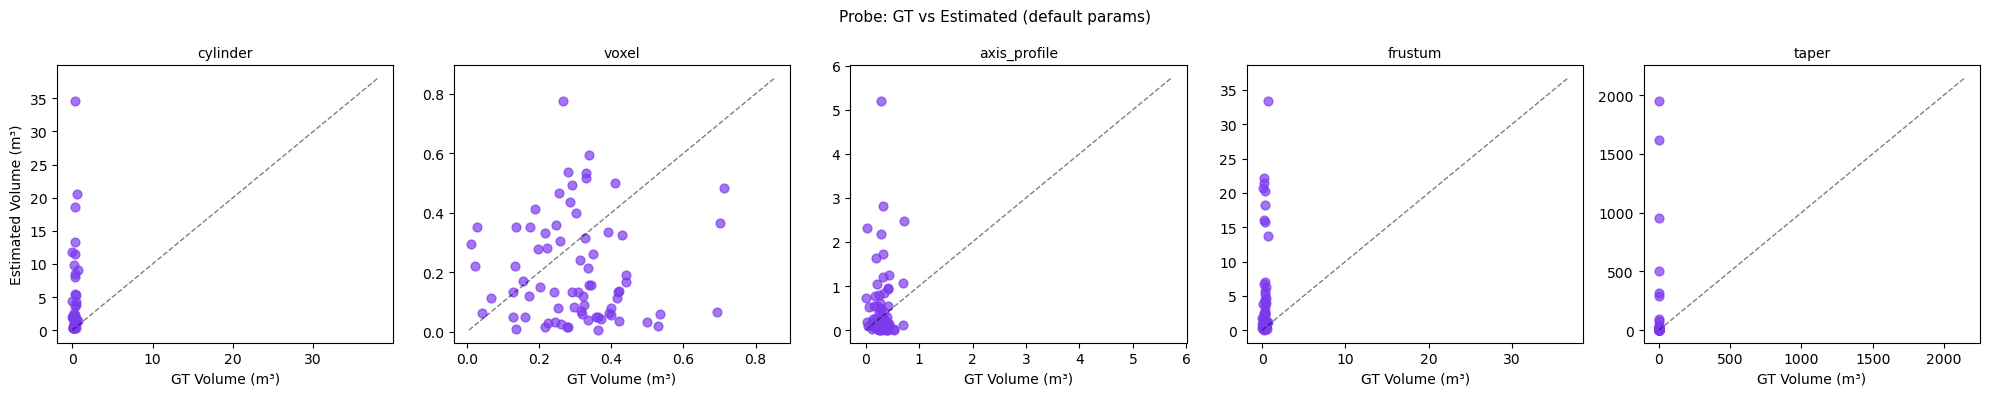

In [6]:
DEFAULT_DBH_PARAMS = dict(offset_range=0.3, n_slices=7, slice_thickness=0.16, ransac_thresh=0.02)

PROBE_CONFIGS = [
    ("cylinder",     dict()),
    ("voxel",        dict(voxel_size=0.08)),
    ("axis_profile", dict(n_slices=20, slice_thickness=0.20, radius_percentile=20.0, min_points_per_slice=5)),
    ("frustum",      dict(n_height_samples=15, slice_thickness=0.20, ransac_thresh=0.05, min_inliers=3)),
    ("taper",        dict(n_height_samples=15, slice_thickness=0.20, ransac_thresh=0.05, min_inliers=3)),
]

probe_rows = []
for tid in matched_tids:
    pts    = points_dict[tid]
    h      = heights_dict[tid]
    tmask  = trunk_masks_dict[tid]
    trunk  = pts[tmask] if tmask.sum() > 10 else pts

    try:
        dbh, _ = estimate_dbh(trunk, method="ensemble", **DEFAULT_DBH_PARAMS)
    except Exception:
        dbh = float("nan")

    for vm, vp in PROBE_CONFIGS:
        try:
            if vm == "cylinder":
                if np.isnan(dbh): raise ValueError("NaN DBH")
                r = estimate_volume(trunk, dbh_cm=dbh, height_m=h, method="cylinder")
            elif vm in ("axis_profile", "frustum", "taper"):
                r = estimate_volume(trunk, method=vm, **vp)
            else:   # voxel → trunk only
                r = estimate_volume(trunk, method=vm, **vp)
            vol = r["volume_m3"]
        except Exception:
            vol = float("nan")

        probe_rows.append({"global_tid": tid, "method": vm, "volume_m3": vol,
                           "dbh_cm": dbh, "height_m": h,
                           "gt_volume": match_dict[tid]["gt_volume"]})

df_probe = pd.DataFrame(probe_rows)

# ── Summary per method ──────────────────────────────────────
total_gt = sel_match_df["gt_volume"].sum()
print(f"{'Method':<14} {'Est. Total':>12} {'Rel Err':>9} {'RMSE':>8}")
print("-" * 48)
for vm, grp in df_probe.groupby("method"):
    vg = grp.dropna(subset=["volume_m3", "gt_volume"])
    if len(vg) == 0:
        print(f"{vm:<14} {'NO DATA':>12}")
        continue
    est = vg["volume_m3"].sum()
    rel = (est - total_gt) / total_gt * 100
    rmse = np.sqrt(((vg["volume_m3"] - vg["gt_volume"])**2).mean())
    print(f"{vm:<14} {est:>12.3f}  {rel:>+8.1f}%  {rmse:>7.4f}")

# ── Per-tree dot plot ────────────────────────────────────────
methods = df_probe["method"].unique()
fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 4), sharey=False)
for ax, vm in zip(axes, methods):
    sub = df_probe[df_probe["method"] == vm].dropna(subset=["volume_m3", "gt_volume"])
    ax.scatter(sub["gt_volume"], sub["volume_m3"], alpha=0.7, s=40, color="#7c3aed")
    mn = min(sub["gt_volume"].min(), sub["volume_m3"].min()) * 0.9
    mx = max(sub["gt_volume"].max(), sub["volume_m3"].max()) * 1.1
    ax.plot([mn, mx], [mn, mx], "k--", lw=1, alpha=0.5)
    ax.set_title(vm, fontsize=10)
    ax.set_xlabel("GT Volume (m³)")
    if ax == axes[0]: ax.set_ylabel("Estimated Volume (m³)")
plt.suptitle("Probe: GT vs Estimated (default params)", fontsize=11)
plt.tight_layout()
plt.show()



## 5. Full Parallel Grid Search
Adjust the grids below if the probe revealed any method needs different ranges.



In [7]:
dbh_grids = {
    "ensemble":     [{"offset_range": o, "n_slices": n, "slice_thickness": st, "ransac_thresh": rt}
                     for o in [0.2, 0.3, 0.4] for n in [5, 7, 10] for st in [0.10, 0.16, 0.20] for rt in [0.01, 0.02, 0.03]],
    "single_ransac":[{"slice_thickness": st, "ransac_thresh": rt}
                     for st in [0.10, 0.16, 0.20] for rt in [0.01, 0.02, 0.03]],
    "ls":           [{"slice_thickness": st} for st in [0.10, 0.16, 0.20]],
}

volume_grids = {
    "cylinder":     [{}],
    "voxel":        [{"voxel_size": vs} for vs in [0.05, 0.07, 0.08, 0.10, 0.12]],
    "axis_profile": [{"n_slices": ns, "slice_thickness": st, "radius_percentile": rp, "min_points_per_slice": mp}
                     for ns in [10, 15, 20, 30] for st in [0.15, 0.20, 0.30]
                     for rp in [15.0, 20.0, 25.0, 30.0] for mp in [5, 10]],
    "frustum":      [{"n_height_samples": nh, "slice_thickness": st, "ransac_thresh": rt, "min_inliers": 3}
                     for nh in [10, 15, 20] for st in [0.15, 0.20, 0.30] for rt in [0.04, 0.06, 0.08, 0.10]],
    "taper":        [{"n_height_samples": nh, "slice_thickness": st, "ransac_thresh": rt, "min_inliers": 3}
                     for nh in [10, 15, 20] for st in [0.15, 0.20, 0.30] for rt in [0.04, 0.06, 0.08, 0.10]],
}

DEF_DBH = "ensemble"
DEF_DBH_P = tuple(sorted(DEFAULT_DBH_PARAMS.items()))

tasks = []
for dm, grids in dbh_grids.items():
    for g in grids:
        for tid in matched_tids:
            tasks.append((tid, dm, tuple(sorted(g.items())), "cylinder", ()))

for vm, grids in volume_grids.items():
    if vm == "cylinder": continue
    for g in grids:
        for tid in matched_tids:
            tasks.append((tid, DEF_DBH, DEF_DBH_P, vm, tuple(sorted(g.items()))))

print(f"Total tasks: {len(tasks):,}")

results = []
with ProcessPoolExecutor(max_workers=NUM_WORKERS, initializer=_init,
                         initargs=(points_dict, heights_dict, trunk_masks_dict)) as exe:
    futs = [exe.submit(_run, t) for t in tasks]
    for fut in tqdm(as_completed(futs), total=len(futs), desc="Grid Search"):
        results.append(fut.result())

df_res = pd.DataFrame(results)
df_res["gt_volume"] = df_res["global_tid"].map(lambda t: match_dict[t]["gt_volume"])
df_res["gt_dbh"]    = df_res["global_tid"].map(lambda t: match_dict[t]["gt_dbh"])
df_res["plot_id"]   = df_res["global_tid"].map(lambda t: match_dict[t]["plot_id"])
total_gt = sel_match_df["gt_volume"].sum()
print(f"Done. Total GT volume for matched trees: {total_gt:.3f} m³")



Total tasks: 19,684


Grid Search:   0%|          | 0/19684 [00:00<?, ?it/s]

Done. Total GT volume for matched trees: 22.307 m³


## 6. Evaluate — Per-Method Best Results


In [8]:
rows = []
for (dm, dp, vm, vp), grp in df_res.groupby(["dbh_method","dbh_params","volume_method","volume_params"]):
    vg = grp.dropna(subset=["volume_m3", "gt_volume"])
    if len(vg) < 3: continue
    est   = vg["volume_m3"].sum()
    rel   = (est - total_gt) / total_gt * 100
    rmse  = np.sqrt(((vg["volume_m3"] - vg["gt_volume"])**2).mean())
    mae   = (vg["volume_m3"] - vg["gt_volume"]).abs().mean()
    corr  = vg["volume_m3"].corr(vg["gt_volume"])
    rows.append({"dbh_method": dm, "volume_method": vm,
                 "dbh_params": dp, "volume_params": vp,
                 "n_trees": len(vg), "est_total_m3": est,
                 "plot_rel_err_pct": rel, "abs_plot_err": abs(rel),
                 "rmse_m3": rmse, "mae_m3": mae, "corr": corr})

df_eval = pd.DataFrame(rows)
# Primary sort: per-tree RMSE (most important for tree-level accuracy)
df_eval.sort_values("rmse_m3", inplace=True)

print("╔══ BEST CONFIGURATION PER METHOD (ranked by per-tree RMSE) ══════════╗")
best_per_method_rmse = []
best_per_method_plot = []
for vm in df_eval["volume_method"].unique():
    sub = df_eval[df_eval["volume_method"] == vm]
    best_rmse = sub.iloc[0]             # best for individual trees
    best_plot = sub.sort_values("abs_plot_err").iloc[0]   # best for plot total
    best_per_method_rmse.append(best_rmse)
    best_per_method_plot.append(best_plot)

    dp_str = best_rmse["dbh_params"][:55] + "…" if len(best_rmse["dbh_params"]) > 55 else best_rmse["dbh_params"]
    vp_str = best_rmse["volume_params"][:55] + "…" if len(best_rmse["volume_params"]) > 55 else best_rmse["volume_params"]
    print(f"\n  [{vm.upper()}]")
    print(f"    Best by RMSE  → Tree RMSE={best_rmse['rmse_m3']:.4f} m³  |  Plot err={best_rmse['plot_rel_err_pct']:+.1f}%")
    print(f"    Best by Plot  → Tree RMSE={best_plot['rmse_m3']:.4f} m³  |  Plot err={best_plot['plot_rel_err_pct']:+.1f}%")
    print(f"    DBH params   : {dp_str}")
    print(f"    Volume params: {vp_str}")

df_best_rmse = pd.DataFrame(best_per_method_rmse).sort_values("rmse_m3")
df_best_plot = pd.DataFrame(best_per_method_plot).sort_values("abs_plot_err")
print("╚══════════════════════════════════════════════════════════════════════╝")



╔══ BEST CONFIGURATION PER METHOD (ranked by per-tree RMSE) ══════════╗

  [VOXEL]
    Best by RMSE  → Tree RMSE=0.2459 m³  |  Plot err=-32.4%
    Best by Plot  → Tree RMSE=0.3416 m³  |  Plot err=+19.5%
    DBH params   : {'n_slices': 7, 'offset_range': 0.3, 'ransac_thresh': 0…
    Volume params: {'voxel_size': 0.08}

  [AXIS_PROFILE]
    Best by RMSE  → Tree RMSE=0.3750 m³  |  Plot err=-29.8%
    Best by Plot  → Tree RMSE=0.7249 m³  |  Plot err=-1.9%
    DBH params   : {'n_slices': 7, 'offset_range': 0.3, 'ransac_thresh': 0…
    Volume params: {'min_points_per_slice': 10, 'n_slices': 15, 'radius_pe…

  [CYLINDER]
    Best by RMSE  → Tree RMSE=3.5236 m³  |  Plot err=+383.8%
    Best by Plot  → Tree RMSE=6.2638 m³  |  Plot err=+135.2%
    DBH params   : {'n_slices': 5, 'offset_range': 0.2, 'ransac_thresh': 0…
    Volume params: {}

  [FRUSTUM]
    Best by RMSE  → Tree RMSE=5.0470 m³  |  Plot err=+490.3%
    Best by Plot  → Tree RMSE=5.0470 m³  |  Plot err=+490.3%
    DBH params   : {'n_

### 6.1 Per-Tree Scatter — Fixed Best Config per Method
We take the **single best parameter set** per method (lowest per-tree RMSE across all trees) and plot how each matched tree was estimated.  
This is the *realistic scenario*: same params for every tree, as would be deployed in practice.



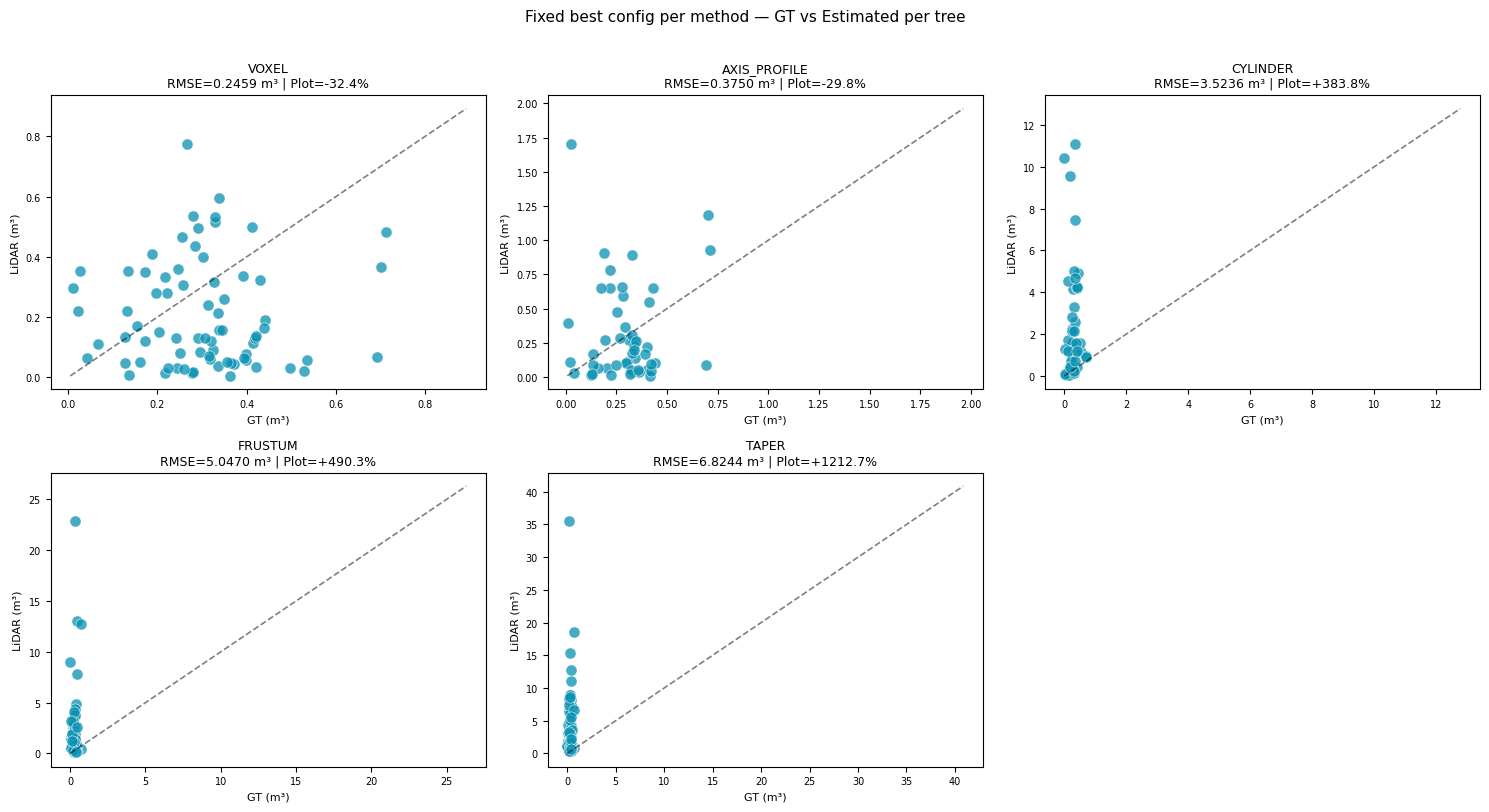

In [9]:
def _get_sub(conf, df):
    vm, dm = conf["volume_method"], conf["dbh_method"]
    if vm == "cylinder":
        return df[(df["volume_method"] == vm) & (df["dbh_method"] == dm) & (df["dbh_params"] == conf["dbh_params"])]
    return df[(df["volume_method"] == vm) & (df["volume_params"] == conf["volume_params"])]

n_methods = len(df_best_rmse)
ncols = 3
nrows = int(np.ceil(n_methods / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, (_, conf) in zip(axes_flat, df_best_rmse.iterrows()):
    sub = _get_sub(conf, df_res).dropna(subset=["volume_m3", "gt_volume"])
    if sub.empty:
        ax.set_visible(False); continue

    ax.scatter(sub["gt_volume"], sub["volume_m3"],
               c="#0891b2", s=65, alpha=0.75, edgecolors="white", linewidths=0.5)

    all_vals = pd.concat([sub["gt_volume"], sub["volume_m3"]])
    mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
    ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)

    ax.set_title(f"{conf['volume_method'].upper()}\nRMSE={conf['rmse_m3']:.4f} m³ | Plot={conf['plot_rel_err_pct']:+.1f}%", fontsize=9)
    ax.set_xlabel("GT (m³)", fontsize=8); ax.set_ylabel("LiDAR (m³)", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes_flat[n_methods:]:
    ax.set_visible(False)

plt.suptitle("Fixed best config per method — GT vs Estimated per tree", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()



### 6.2 Oracle Analysis — Best Config Chosen Per Individual Tree
Here we ask: *"what if, for every individual tree, we could magically pick the exact parameter config that minimised its error?"*  
This represents the **theoretical lower bound** on per-tree RMSE — the best we could ever achieve even with perfect tuning.  
Comparing 6.1 vs 6.2 shows the gap between a fixed deployment config and an oracle.



╔══ ORACLE vs FIXED CONFIG — RMSE per method ══╗
Method           Oracle RMSE   Fixed RMSE      Gap
----------------------------------------------------
  voxel              0.1542        0.2459   +0.0917
  axis_profile       0.1349        0.3750   +0.2401
  cylinder           1.4137        3.5236   +2.1099
  frustum            0.7546        5.0470   +4.2924
  taper             12.3662        6.8244   -5.5417
╚══════════════════════════════════════════════╝


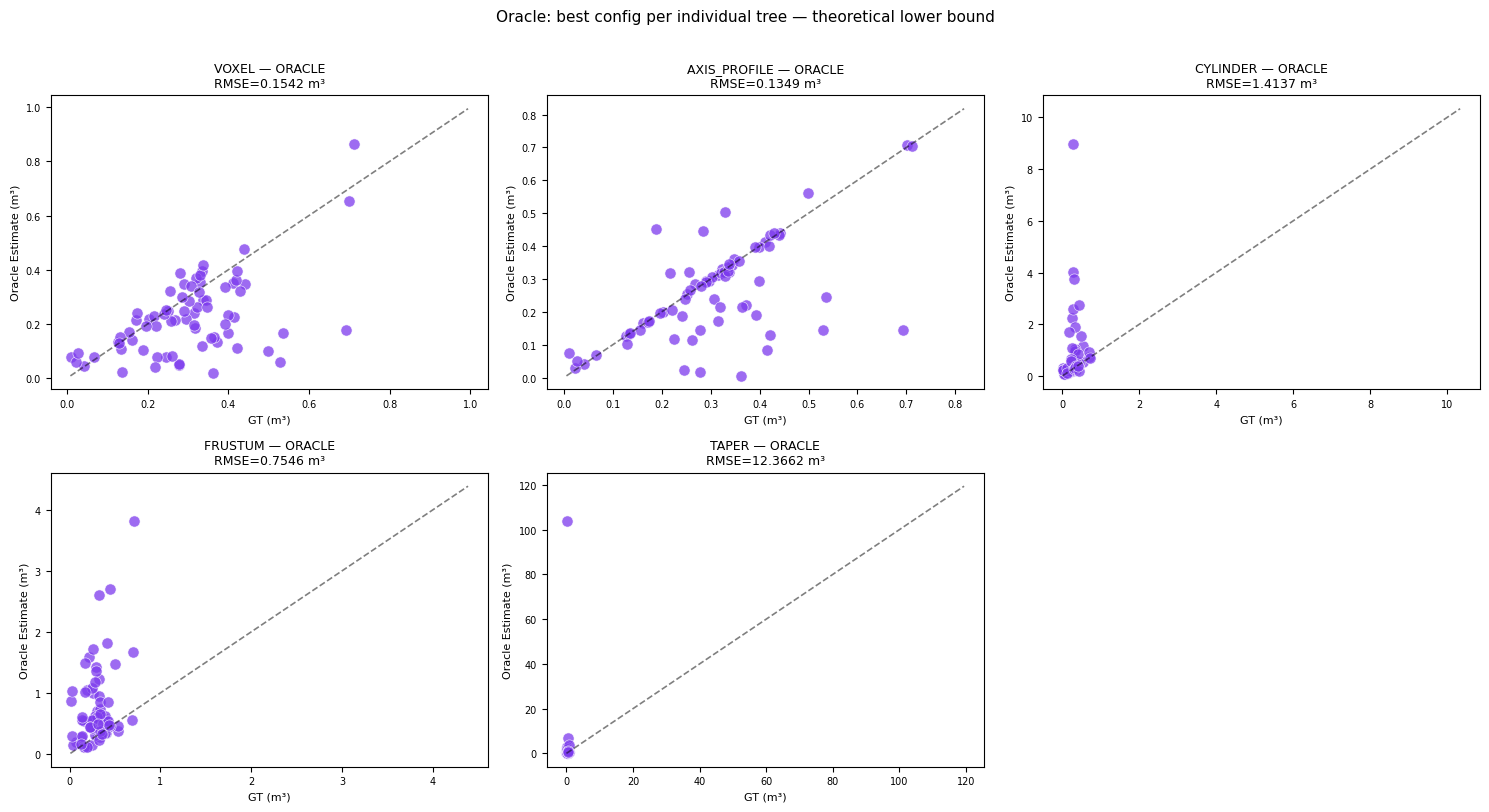

In [10]:
# For each tree × volume_method, find the config with lowest |error|
oracle_rows = []
for vm in df_eval["volume_method"].unique():
    vm_data = df_res[df_res["volume_method"] == vm].dropna(subset=["volume_m3", "gt_volume"])
    if vm_data.empty: continue

    for tid, tree_grp in vm_data.groupby("global_tid"):
        gt = tree_grp["gt_volume"].iloc[0]
        # Best config for this specific tree: lowest absolute error
        best_idx = (tree_grp["volume_m3"] - gt).abs().idxmin()
        best_row  = tree_grp.loc[best_idx]
        oracle_rows.append({
            "global_tid":     tid,
            "volume_method":  vm,
            "oracle_volume":  best_row["volume_m3"],
            "gt_volume":      gt,
            "abs_err":        abs(best_row["volume_m3"] - gt),
            "best_params":    best_row["volume_params"],
        })

df_oracle = pd.DataFrame(oracle_rows)

# Summary table
print("╔══ ORACLE vs FIXED CONFIG — RMSE per method ══╗")
print(f"{'Method':<14} {'Oracle RMSE':>13} {'Fixed RMSE':>12} {'Gap':>8}")
print("-" * 52)
for vm in df_eval["volume_method"].unique():
    fixed_rmse  = df_best_rmse[df_best_rmse["volume_method"] == vm]["rmse_m3"].iloc[0] if vm in df_best_rmse["volume_method"].values else float("nan")
    oracle_sub  = df_oracle[df_oracle["volume_method"] == vm]
    if oracle_sub.empty: continue
    oracle_rmse = np.sqrt((oracle_sub["abs_err"]**2).mean())
    gap = fixed_rmse - oracle_rmse
    print(f"  {vm:<12} {oracle_rmse:>12.4f}  {fixed_rmse:>12.4f}  {gap:>+8.4f}")
print("╚══════════════════════════════════════════════╝")

# Scatter plot oracle
n_methods_o = df_oracle["volume_method"].nunique()
ncols_o = 3
nrows_o = int(np.ceil(n_methods_o / ncols_o))

fig, axes = plt.subplots(nrows_o, ncols_o, figsize=(5 * ncols_o, 4 * nrows_o))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, vm in zip(axes_flat, df_oracle["volume_method"].unique()):
    sub = df_oracle[df_oracle["volume_method"] == vm]
    ax.scatter(sub["gt_volume"], sub["oracle_volume"],
               c="#7c3aed", s=65, alpha=0.75, edgecolors="white", linewidths=0.5)

    all_vals = pd.concat([sub["gt_volume"], sub["oracle_volume"]])
    mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
    ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)

    oracle_rmse = np.sqrt(((sub["oracle_volume"] - sub["gt_volume"])**2).mean())
    ax.set_title(f"{vm.upper()} — ORACLE\nRMSE={oracle_rmse:.4f} m³", fontsize=9)
    ax.set_xlabel("GT (m³)", fontsize=8); ax.set_ylabel("Oracle Estimate (m³)", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes_flat[n_methods_o:]:
    ax.set_visible(False)

plt.suptitle("Oracle: best config per individual tree — theoretical lower bound", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()



## 7. Extrapolation to m³/ha — Top 5 Estimators vs Official GT
We scale each estimator's plot volume to 1 ha (`×25` for 400 m² plots). Because FF3D did not isolate 100% of the trees, we apply an isolation correction factor `(n_living_field / n_matched_lidar)` before scaling.



Official GT (m³/ha) per plot:
Parcela
500    218.32
503    223.43
508    200.72
509    162.69

  voxel | Parcela 500: matched=15, living=28, adj=4.85 m³, extrap=121.2 m³/ha
  voxel | Parcela 503: matched=22, living=28, adj=5.13 m³, extrap=128.1 m³/ha
  voxel | Parcela 508: matched=32, living=33, adj=6.87 m³, extrap=171.7 m³/ha
  voxel | Parcela 509: matched=5, living=15, adj=5.40 m³, extrap=135.1 m³/ha
  → mean 139.0 m³/ha  (err -30.9%)

  voxel | Parcela 500: matched=15, living=28, adj=3.38 m³, extrap=84.5 m³/ha
  voxel | Parcela 503: matched=22, living=28, adj=3.56 m³, extrap=89.1 m³/ha
  voxel | Parcela 508: matched=32, living=33, adj=4.82 m³, extrap=120.5 m³/ha
  voxel | Parcela 509: matched=5, living=15, adj=3.77 m³, extrap=94.3 m³/ha
  → mean 97.1 m³/ha  (err -51.8%)

  voxel | Parcela 500: matched=15, living=28, adj=1.32 m³, extrap=33.1 m³/ha
  voxel | Parcela 503: matched=22, living=28, adj=1.37 m³, extrap=34.3 m³/ha
  voxel | Parcela 508: matched=32, living=33, adj=1.90 m³, ex

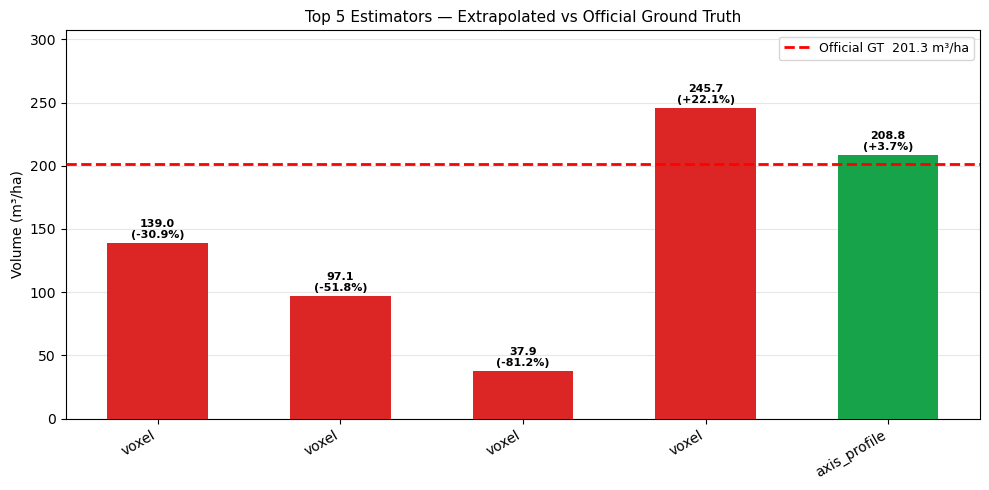

In [11]:
top5 = df_eval.head(5).copy()
gt_ha_by_plot = df_extrap["VTCC (m³/ha)"]
print(f"Official GT (m³/ha) per plot:\n{gt_ha_by_plot.to_string()}\n")
gt_ha_mean = gt_ha_by_plot.mean()

extrap_rows = []
for i, (_, conf) in enumerate(top5.iterrows(), 1):
    vm, dm = conf["volume_method"], conf["dbh_method"]

    if vm == "cylinder":
        sub = df_res[(df_res["volume_method"] == vm) & (df_res["dbh_method"] == dm)
                     & (df_res["dbh_params"] == conf["dbh_params"])]
    else:
        sub = df_res[(df_res["volume_method"] == vm) & (df_res["volume_params"] == conf["volume_params"])]

    sub = sub.dropna(subset=["volume_m3", "gt_volume"])

    per_plot_ha = []
    for pid, pg in sub.groupby("plot_id"):
        n_living  = df_field[(df_field["PAR_CODIGO"] == pid) & df_field["has_gt_volume"]].shape[0]
        n_matched = len(pg)
        if n_matched == 0: continue
        adj_vol  = pg["volume_m3"].sum() * (n_living / n_matched)
        ha_vol   = adj_vol * 25.0   # 400 m² → 1 ha
        per_plot_ha.append(ha_vol)
        print(f"  {vm} | Parcela {pid}: matched={n_matched}, living={n_living}, "
              f"adj={adj_vol:.2f} m³, extrap={ha_vol:.1f} m³/ha")

    mean_ha  = np.mean(per_plot_ha)
    err_pct  = (mean_ha - gt_ha_mean) / gt_ha_mean * 100
    label    = f"{vm}\n({dm[:4]})" if vm == "cylinder" else vm
    extrap_rows.append({"label": label, "m3_ha": mean_ha, "err": err_pct})
    print(f"  → mean {mean_ha:.1f} m³/ha  (err {err_pct:+.1f}%)\n")

# ── Bar chart ───────────────────────────────────────────────
df_ex = pd.DataFrame(extrap_rows)

fig, ax = plt.subplots(figsize=(max(8, len(df_ex) * 2), 5))
colors = ["#16a34a" if abs(r) < 10 else "#ca8a04" if abs(r) < 20 else "#dc2626"
          for r in df_ex["err"]]
x_pos = np.arange(len(df_ex))
bars = ax.bar(x_pos, df_ex["m3_ha"], color=colors, width=0.55, zorder=3)
ax.set_xticks(x_pos)
ax.set_xticklabels(df_ex["label"])
ax.axhline(gt_ha_mean, color="red", linestyle="--", linewidth=2, zorder=4,
           label=f"Official GT  {gt_ha_mean:.1f} m³/ha")

# Error labels
for bar, (_, row) in zip(bars, df_ex.iterrows()):
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + gt_ha_mean * 0.01,
            f"{y:.1f}\n({row['err']:+.1f}%)", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_ylabel("Volume (m³/ha)")
ax.set_ylim(0, max(df_ex["m3_ha"].max(), gt_ha_mean) * 1.25)
ax.set_title("Top 5 Estimators — Extrapolated vs Official Ground Truth", fontsize=11)
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3, zorder=0)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()



## 8. DBH Evaluation — Fixed vs Oracle
We now perform the same per-tree analysis (Fixed Best Config vs Oracle) for Diameter at Breast Height (DBH).


In [12]:

# Filter to unique DBH results per tree
# Since multiple volume methods share the same DBH runs, we drop duplicates
df_dbh = df_res.drop_duplicates(subset=["global_tid", "dbh_method", "dbh_params"]).copy()
df_dbh = df_dbh.dropna(subset=["dbh_cm", "gt_dbh"])

rows_dbh = []
for (dm, dp), grp in df_dbh.groupby(["dbh_method", "dbh_params"]):
    if len(grp) < 3: continue
    rmse = np.sqrt(((grp["dbh_cm"] - grp["gt_dbh"])**2).mean())
    mae = (grp["dbh_cm"] - grp["gt_dbh"]).abs().mean()
    rows_dbh.append({"dbh_method": dm, "dbh_params": dp, "rmse_cm": rmse, "mae_cm": mae})

df_eval_dbh = pd.DataFrame(rows_dbh).sort_values("rmse_cm")

print("╔══ BEST DBH CONFIGURATION PER METHOD (ranked by per-tree RMSE) ══╗")
best_dbh_fixed = []
for dm in df_eval_dbh["dbh_method"].unique():
    sub = df_eval_dbh[df_eval_dbh["dbh_method"] == dm]
    best = sub.iloc[0]
    best_dbh_fixed.append(best)
    dp_str = best["dbh_params"][:70] + "…" if len(best["dbh_params"]) > 70 else best["dbh_params"]
    print(f"  [{dm.upper()}]")
    print(f"    Tree RMSE    : {best['rmse_cm']:.4f} cm (MAE: {best['mae_cm']:.4f} cm)")
    print(f"    DBH params   : {dp_str}")
df_best_dbh = pd.DataFrame(best_dbh_fixed).sort_values("rmse_cm")
print("╚═════════════════════════════════════════════════════════════════╝")



╔══ BEST DBH CONFIGURATION PER METHOD (ranked by per-tree RMSE) ══╗
  [ENSEMBLE]
    Tree RMSE    : 40.7101 cm (MAE: 31.5759 cm)
    DBH params   : {'n_slices': 7, 'offset_range': 0.4, 'ransac_thresh': 0.03, 'slice_thi…
  [LS]
    Tree RMSE    : 50.5949 cm (MAE: 37.7781 cm)
    DBH params   : {'slice_thickness': 0.16}
  [SINGLE_RANSAC]
    Tree RMSE    : 59.0733 cm (MAE: 40.0395 cm)
    DBH params   : {'ransac_thresh': 0.01, 'slice_thickness': 0.1}
╚═════════════════════════════════════════════════════════════════╝


### 8.1 Per-Tree Scatter — Fixed Best DBH Config


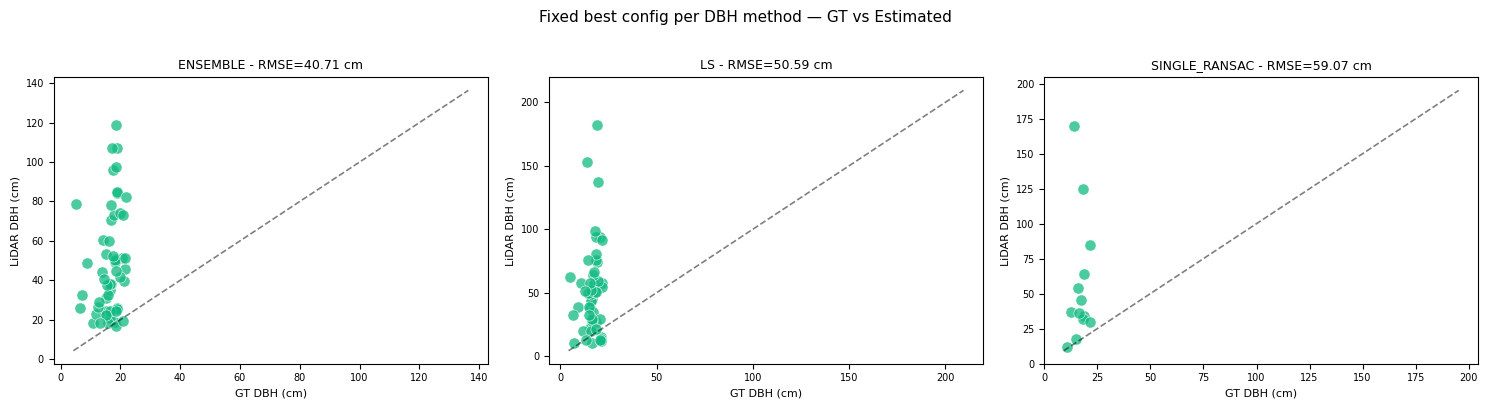

In [13]:

n_methods = len(df_best_dbh)
ncols = 3
nrows = int(np.ceil(n_methods / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, (_, conf) in zip(axes_flat, df_best_dbh.iterrows()):
    dm = conf["dbh_method"]
    sub = df_dbh[(df_dbh["dbh_method"] == dm) & (df_dbh["dbh_params"] == conf["dbh_params"])]
    
    ax.scatter(sub["gt_dbh"], sub["dbh_cm"], c="#10b981", s=65, alpha=0.75, edgecolors="white", linewidths=0.5)
    
    all_vals = pd.concat([sub["gt_dbh"], sub["dbh_cm"]])
    mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
    ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)
    
    ax.set_title(f"{dm.upper()} - RMSE={conf['rmse_cm']:.2f} cm", fontsize=9)
    ax.set_xlabel("GT DBH (cm)", fontsize=8); ax.set_ylabel("LiDAR DBH (cm)", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes_flat[n_methods:]: ax.set_visible(False)
plt.suptitle("Fixed best config per DBH method — GT vs Estimated", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()



### 8.2 Oracle Analysis — Best DBH Config Chosen Per Individual Tree


╔══ ORACLE vs FIXED CONFIG — DBH RMSE per method ══╗
Method            Oracle RMSE   Fixed RMSE      Gap
----------------------------------------------------
  ensemble            14.3624       40.7101  +26.3477
  ls                  49.6520       50.5949   +0.9429
  single_ransac       41.9907       59.0733  +17.0826
╚══════════════════════════════════════════════════╝


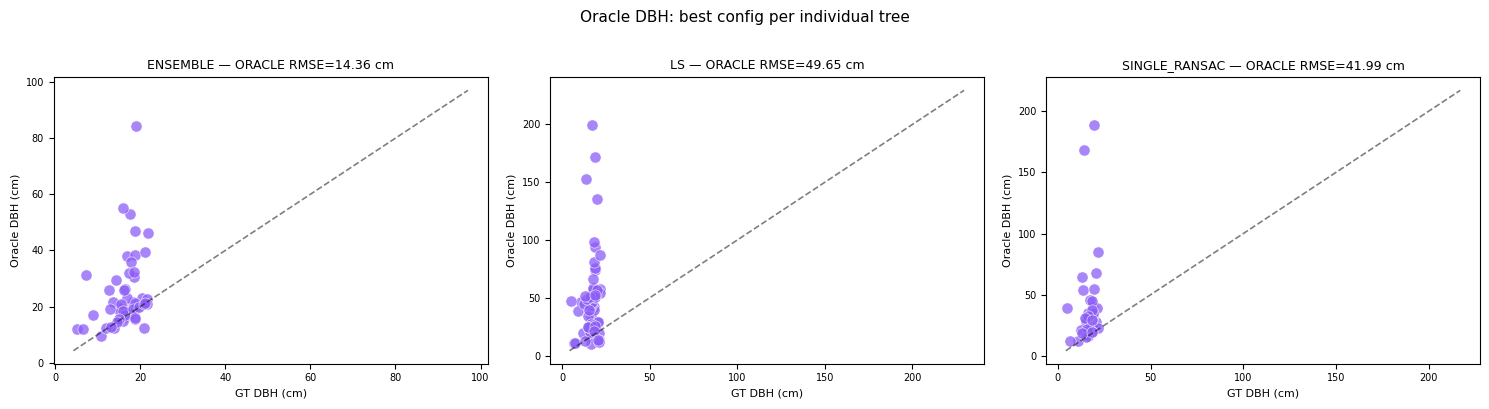

In [14]:

oracle_dbh_rows = []
for dm in df_eval_dbh["dbh_method"].unique():
    dm_data = df_dbh[df_dbh["dbh_method"] == dm]
    
    for tid, tree_grp in dm_data.groupby("global_tid"):
        gt = tree_grp["gt_dbh"].iloc[0]
        best_idx = (tree_grp["dbh_cm"] - gt).abs().idxmin()
        best_row = tree_grp.loc[best_idx]
        oracle_dbh_rows.append({
            "global_tid": tid, "dbh_method": dm, 
            "oracle_dbh": best_row["dbh_cm"], "gt_dbh": gt, 
            "abs_err": abs(best_row["dbh_cm"] - gt)
        })

df_oracle_dbh = pd.DataFrame(oracle_dbh_rows)

print("╔══ ORACLE vs FIXED CONFIG — DBH RMSE per method ══╗")
print(f"{'Method':<16} {'Oracle RMSE':>12} {'Fixed RMSE':>12} {'Gap':>8}")
print("-" * 52)
for dm in df_eval_dbh["dbh_method"].unique():
    fixed_rmse = df_best_dbh[df_best_dbh["dbh_method"] == dm]["rmse_cm"].iloc[0]
    oracle_sub = df_oracle_dbh[df_oracle_dbh["dbh_method"] == dm]
    oracle_rmse = np.sqrt((oracle_sub["abs_err"]**2).mean())
    gap = fixed_rmse - oracle_rmse
    print(f"  {dm:<14} {oracle_rmse:>12.4f}  {fixed_rmse:>12.4f}  {gap:>+8.4f}")
print("╚══════════════════════════════════════════════════╝")

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, dm in zip(axes_flat, df_oracle_dbh["dbh_method"].unique()):
    sub = df_oracle_dbh[df_oracle_dbh["dbh_method"] == dm]
    ax.scatter(sub["gt_dbh"], sub["oracle_dbh"], c="#8b5cf6", s=65, alpha=0.75, edgecolors="white", linewidths=0.5)
    
    all_vals = pd.concat([sub["gt_dbh"], sub["oracle_dbh"]])
    mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
    ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)
    
    o_rmse = np.sqrt(((sub["oracle_dbh"] - sub["gt_dbh"])**2).mean())
    ax.set_title(f"{dm.upper()} — ORACLE RMSE={o_rmse:.2f} cm", fontsize=9)
    ax.set_xlabel("GT DBH (cm)", fontsize=8); ax.set_ylabel("Oracle DBH (cm)", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes_flat[len(df_oracle_dbh["dbh_method"].unique()):]: ax.set_visible(False)
plt.suptitle("Oracle DBH: best config per individual tree", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()



## 9. Controlled Evaluation — Well-Segmented Trees Only
Often, volume estimation errors are driven by **poor point cloud segmentation** (e.g., FF3D merging two trees or including noise) rather than the mathematical volume method itself. 

By providing a specific list of `tree_id`s that you have visually confirmed are *perfectly segmented*, we can compare the biometric error of this "Well-Segmented" subset versus the "Whole Plot" to isolate where the error is truly coming from.


Requested trees: [5000029, 5000036, 5000039]
Available in section 6.2: [5000039]
Unavailable in section 6.2 (not GT-matched): [5000029, 5000036]
Evaluating 1 well-segmented trees with their per-tree best configurations...
╔══ VOLUME: Oracle Whole Plot vs Well-Segmented Subset ══╗
Method           Oracle All RMSE   Well-Seg RMSE  Improvement
------------------------------------------------------------------
  voxel                0.1542 m³       0.0559 m³       +63.8%
  axis_profile         0.1349 m³       0.0017 m³       +98.7%
  cylinder             1.4137 m³       3.7319 m³      -164.0%
  frustum              0.7546 m³       1.1276 m³       -49.4%
  taper               12.3662 m³       2.4881 m³       +79.9%
╚══════════════════════════════════════════════════════════╝


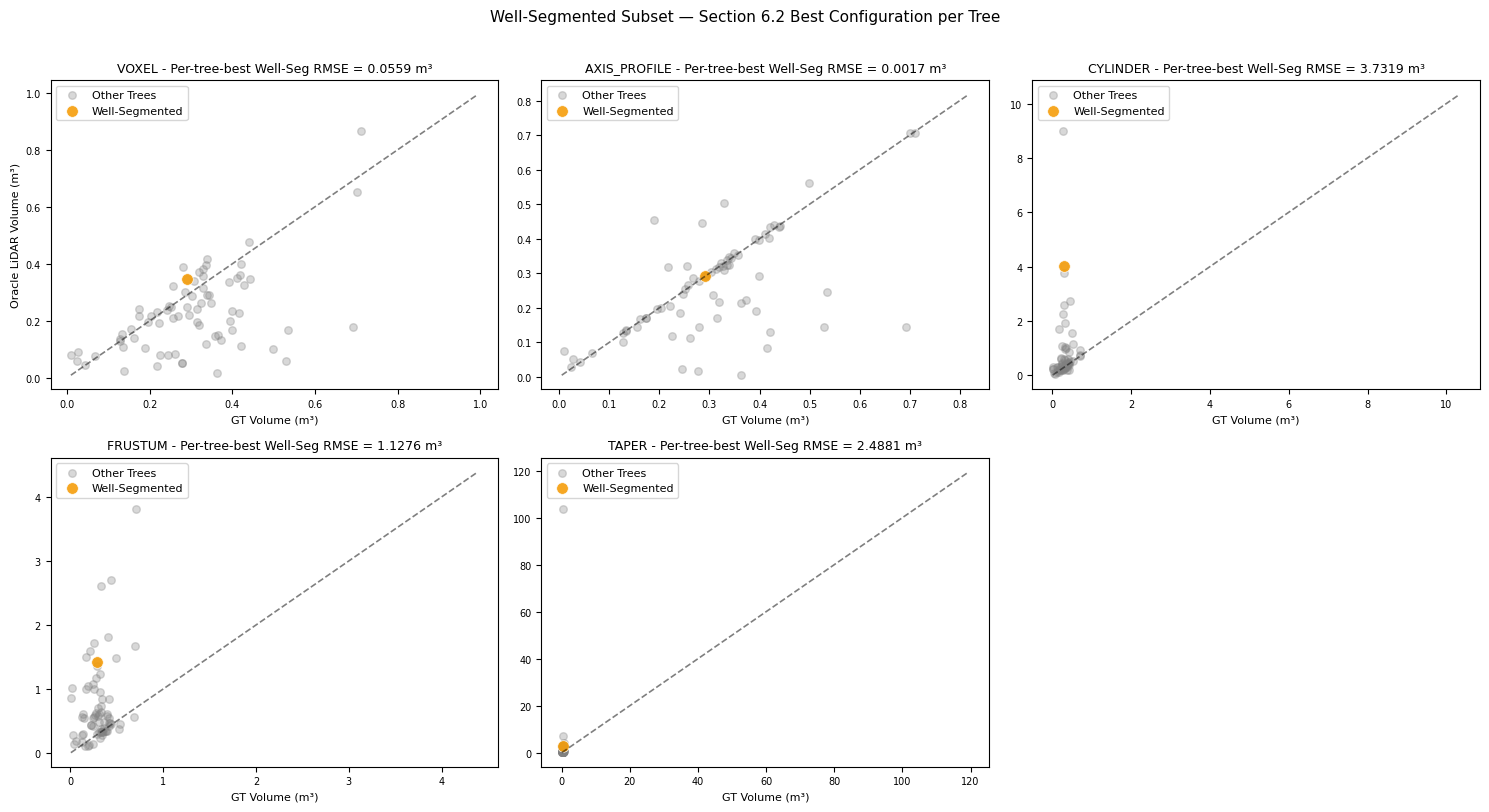

In [15]:
# Define the perfectly segmented trees you want to evaluate.
# Format: { plot_id: [tree_id_1, tree_id_2, ...] }
# Example: WELL_SEGMENTED_TREES = { 500: [15, 18], 503: [1, 5, 10] }

WELL_SEGMENTED_TREES = {
    500: [29,36,39], # Replace with your specific tree IDs!
}

# Section 6.2 (df_oracle) stores the best configuration for each tree and method.
# It is selected by the lowest absolute error against that tree's GT volume.
well_segmented_tids = []
for pid, tids in WELL_SEGMENTED_TREES.items():
    well_segmented_tids.extend([t + pid * 10000 for t in tids])

oracle_tids = set(df_oracle["global_tid"])
valid_well_seg_tids = [t for t in well_segmented_tids if t in oracle_tids]
missing_well_seg_tids = [t for t in well_segmented_tids if t not in oracle_tids]

print(f"Requested trees: {well_segmented_tids}")
print(f"Available in section 6.2: {valid_well_seg_tids}")
if missing_well_seg_tids:
    print(f"Unavailable in section 6.2 (not GT-matched): {missing_well_seg_tids}")

if not valid_well_seg_tids:
    print("No requested trees have a section 6.2 oracle result. Check matching and GT volume availability.")
else:
    print(f"Evaluating {len(valid_well_seg_tids)} well-segmented trees with their per-tree best configurations...")

    print("╔══ VOLUME: Oracle Whole Plot vs Well-Segmented Subset ══╗")
    print(f"{'Method':<14} {'Oracle All RMSE':>17} {'Well-Seg RMSE':>15} {'Improvement':>12}")
    print("-" * 66)

    for vm in df_oracle["volume_method"].unique():
        oracle_all = df_oracle[df_oracle["volume_method"] == vm]
        oracle_well = oracle_all[oracle_all["global_tid"].isin(valid_well_seg_tids)]

        rmse_all = np.sqrt(((oracle_all["oracle_volume"] - oracle_all["gt_volume"])**2).mean())
        rmse_well = np.sqrt(((oracle_well["oracle_volume"] - oracle_well["gt_volume"])**2).mean()) if not oracle_well.empty else float("nan")
        imp = ((rmse_all - rmse_well) / rmse_all * 100) if not np.isnan(rmse_well) else 0

        print(f"  {vm:<12} {rmse_all:>14.4f} m³ {rmse_well:>12.4f} m³ {imp:>+11.1f}%")

    print("╚══════════════════════════════════════════════════════════╝")

    # --- Scatter plot using each tree's own best section 6.2 estimate ---
    volume_methods = df_oracle["volume_method"].unique()
    n_methods = len(volume_methods)
    ncols = 3
    nrows = int(np.ceil(n_methods / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax, vm in zip(axes_flat, volume_methods):
        oracle_all = df_oracle[df_oracle["volume_method"] == vm]
        oracle_well = oracle_all[oracle_all["global_tid"].isin(valid_well_seg_tids)]

        # Plot all trees' per-tree-best estimates in the background.
        ax.scatter(oracle_all["gt_volume"], oracle_all["oracle_volume"],
                   c="gray", s=30, alpha=0.3, label="Other Trees")

        if not oracle_well.empty:
            ax.scatter(oracle_well["gt_volume"], oracle_well["oracle_volume"],
                       c="#f59e0b", s=70, alpha=0.9, edgecolors="white",
                       linewidths=0.5, label="Well-Segmented")

        all_vals = pd.concat([oracle_all["gt_volume"], oracle_all["oracle_volume"]])
        mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
        ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)

        rmse_well = np.sqrt(((oracle_well["oracle_volume"] - oracle_well["gt_volume"])**2).mean()) if not oracle_well.empty else float("nan")
        ax.set_title(f"{vm.upper()} - Per-tree-best Well-Seg RMSE = {rmse_well:.4f} m³", fontsize=9)
        ax.set_xlabel("GT Volume (m³)", fontsize=8)
        if ax == axes_flat[0]: ax.set_ylabel("Oracle LiDAR Volume (m³)", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.legend(fontsize=8)

    for ax in axes_flat[n_methods:]:
        ax.set_visible(False)
    plt.suptitle("Well-Segmented Subset — Section 6.2 Best Configuration per Tree", fontsize=11, y=1.01)
    plt.tight_layout()
    plt.show()


In [16]:
print("Requested:", well_segmented_tids)
print("Valid:", valid_well_seg_tids)
print("Excluded:", [t for t in well_segmented_tids if t not in matched_tids])

Requested: [5000029, 5000036, 5000039]
Valid: [5000039]
Excluded: [5000029, 5000036]
